In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

In [2]:
COUNTRY = "DE"
START_DATE = "20210101"
END_DATE = "20260101"

In [3]:
def load_merged(path):
    """Read a saved merged CSV back with a UTC DatetimeIndex named 'time'."""
    df = pd.read_csv(path, index_col="time", float_precision="round_trip")
    df.index = pd.to_datetime(df.index, utc=True)
    return df

In [4]:
merged_path = Path(f"../data/merged/merged_hourly_{COUNTRY}_{START_DATE}_{END_DATE}.csv")
merged_clean = load_merged(merged_path)

### Check difference between Load (Demand) and Generation (Supply)

16 generation columns used
count    43823.00
mean        -2.42
std          6.27
min        -20.88
25%         -7.29
50%         -2.61
75%          2.30
max         16.94
dtype: float64


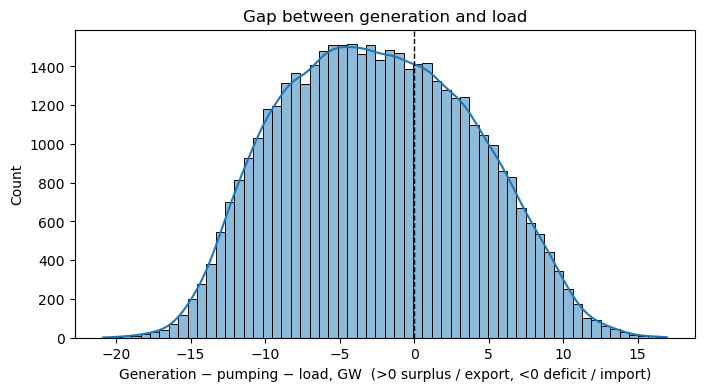

In [5]:
pump_col = "Hydro_Pumped_Storage_Consumption_MW"
weather_cols = ["temperature_2m", "apparent_temperature", "relative_humidity_2m", "precipitation",
                "cloud_cover", "shortwave_radiation", "wind_speed_10m", "wind_speed_100m"]
gen_cols = [c for c in merged_clean.columns if c not in ["Total_Load_MW", pump_col, *weather_cols]]

total_gen = merged_clean[gen_cols].sum(axis=1)
gap = total_gen - merged_clean[pump_col] - merged_clean["Total_Load_MW"]   # >0 surplus (export), <0 deficit (import)

print(f"{len(gen_cols)} generation columns used")
print((gap / 1000).describe().round(2))   # in GW

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(gap / 1000, bins=60, kde=True, ax=ax)
ax.axvline(0, color="k", ls="--", lw=1)
ax.set_xlabel("Generation − pumping − load, GW  (>0 surplus / export, <0 deficit / import)")
ax.set_title("Gap between generation and load")
plt.show()